In [1]:
from pathlib import Path
import os

print("Diretório atual:", os.getcwd())
print("Preprocessing na raiz:", Path("preprocessing.py").exists())
print("Preprocessing na pasta acima:", Path("../preprocessing.py").exists())

Diretório atual: /home/victor/code/Victorpeereiraa/cross_genre_music_discovery/notebooks
Preprocessing na raiz: False
Preprocessing na pasta acima: True


In [2]:
import sys
from pathlib import Path

project_root = Path.cwd().parent

sys.path.insert(0, str(project_root))

In [3]:
from sklearn.mixture import GaussianMixture
from preprocessing import preprocessing , PCA_transform
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import davies_bouldin_score , silhouette_score , silhouette_samples

# Lendo o DataFrame

In [4]:
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")

# Preprocess + PCA

In [5]:
X_scaled, df_metadata, scaler, features = preprocessing(df)

In [6]:
df_pca3 = PCA_transform(X_scaled)
df_pca3

,PC0,PC1,PC2
0,0.694357,1.254424,0.393031
1,-3.139431,1.086433,0.007441
2,-1.294223,-0.268110,-0.509493
3,-3.184718,-0.502834,0.030796
4,-0.850054,0.136656,-0.208913
...,...,...,...
88746,-3.720461,-1.995120,0.296020
88747,-4.912135,-1.116462,0.229542
88748,-0.972261,1.797437,-0.348436
88749,-0.434076,0.238729,-0.477846


# Training GMM model with 10 components and full covariance

In [7]:
gmm = GaussianMixture(
    n_components=10,
    covariance_type='full',
    random_state=42
)

In [8]:
gmm.fit(df_pca3)

,n_components,10
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [9]:
#verificar se houve convergencia
print(gmm.converged_)
print(gmm.n_iter_)

True
21


In [10]:
#verificando a divisão dos clusters

labels_pca3 = gmm.predict(df_pca3)

pd.Series(labels_pca3).value_counts().sort_index()

0    11572
1    13984
2     6160
3     2369
4     3845
5     8014
6    14161
7    10312
8    10246
9     8088
Name: count, dtype: int64

In [11]:
# Analisando o grau de certeza
probabilities_pca3 = gmm.predict_proba(df_pca3)

confidence_pca3 = probabilities_pca3.max(axis=1)

print("Confiança média:", confidence_pca3.mean())

Confiança média: 0.7084010120490504


In [12]:
# Verificando BIC e AIC

print("BIC:", gmm.bic(df_pca3))
print("AIC:", gmm.aic(df_pca3))

BIC: 740825.0938221387
AIC: 739895.1284146257


# Training GMM model with 5 components and full covariance

In [13]:
gmm_5 = GaussianMixture(
    n_components=5,
    covariance_type='full',
    random_state=42
)

In [14]:
gmm_5.fit(df_pca3)

,n_components,5
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [15]:
#verificar se houve convergencia
print(gmm_5.converged_)
print(gmm_5.n_iter_)

True
26


In [16]:
#verificando a divisão dos clusters

labels_5 = gmm_5.predict(df_pca3)

pd.Series(labels_5).value_counts().sort_index()

0    22531
1    27566
2    11712
3     9718
4    17224
Name: count, dtype: int64

In [17]:
# Analisando o grau de certeza
probabilities_5 = gmm_5.predict_proba(df_pca3)

confidence_5 = probabilities_5.max(axis=1)

print("Confiança média:", confidence_5.mean())

Confiança média: 0.7888156096921813


In [18]:
# Verificando BIC e AIC

print("BIC:", gmm_5.bic(df_pca3))
print("AIC:", gmm_5.aic(df_pca3))

BIC: 749889.1657974091
AIC: 749428.87988864


# Training GMM model with 15 components and full covariance

In [19]:
gmm_15 = GaussianMixture(
    n_components=15,
    covariance_type='full',
    random_state=42
)

In [20]:
gmm_15.fit(df_pca3)

,n_components,15
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [21]:
#verificar se houve convergencia
print(gmm_15.converged_)
print(gmm_15.n_iter_)

True
24


In [22]:
#verificando a divisão dos clusters

labels_15 = gmm_15.predict(df_pca3)

pd.Series(labels_15).value_counts().sort_index()

0      7296
1     13588
2      1990
3      2252
4      3747
5      3723
6      8870
7      6118
8      6735
9      7497
10     8376
11     4126
12     6800
13     5929
14     1704
Name: count, dtype: int64

In [23]:
# Analisando o grau de certeza
probabilities_15 = gmm_15.predict_proba(df_pca3)

confidence_15 = probabilities_15.max(axis=1)

print("Confiança média:", confidence_15.mean())

Confiança média: 0.6404601565896602


In [24]:
# Verificando BIC e AIC

print("BIC:", gmm_15.bic(df_pca3))
print("AIC:", gmm_15.aic(df_pca3))

BIC: 737621.0040790804
AIC: 736221.3591728234


# Training GMM model with 20 components and full covariance

In [25]:
gmm_20 = GaussianMixture(
    n_components=20,
    covariance_type='full',
    random_state=42
)

In [26]:
gmm_20.fit(df_pca3)

,n_components,20
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [27]:
#verificar se houve convergencia
print(gmm_20.converged_)
print(gmm_20.n_iter_)

True
17


In [28]:
#verificando a divisão dos clusters

labels_20 = gmm_20.predict(df_pca3)

pd.Series(labels_20).value_counts().sort_index()

0     4511
1     7374
2     1381
3     2905
4     3313
5     2715
6     8261
7     5098
8     4753
9     5696
10    7218
11    5822
12    2009
13    2405
14     604
15    3478
16    7093
17    5731
18    5728
19    2656
Name: count, dtype: int64

In [29]:
# Analisando o grau de certeza
probabilities_20 = gmm_20.predict_proba(df_pca3)

confidence_20 = probabilities_20.max(axis=1)

print("Confiança média:", confidence_20.mean())

Confiança média: 0.6398442498373176


In [30]:
# Verificando BIC e AIC

print("BIC:", gmm_20.bic(df_pca3))
print("AIC:", gmm_20.aic(df_pca3))

BIC: 737160.1261568295
AIC: 735290.8017518284


# Training GMM model with 30 components and full covariance

In [31]:
gmm_30 = GaussianMixture(
    n_components=30,
    covariance_type='full',
    random_state=42
)

In [32]:
gmm_30.fit(df_pca3)

,n_components,30
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [33]:
#verificar se houve convergencia
print(gmm_30.converged_)
print(gmm_30.n_iter_)

True
19


In [34]:
#verificando a divisão dos clusters

labels_30 = gmm_30.predict(df_pca3)

pd.Series(labels_30).value_counts().sort_index()

0     1309
1     3570
2     2176
3     3127
4     3374
5     4674
6     2352
7     1199
8     3151
9     4463
10    1545
11     351
12    4493
13    1491
14    4160
15    3221
16     944
17    3823
18     912
19    4241
20    4648
21    3001
22    1631
23    5819
24    1658
25    2046
26    1626
27    5485
28    5660
29    2601
Name: count, dtype: int64

In [35]:
# Analisando o grau de certeza
probabilities_30 = gmm_30.predict_proba(df_pca3)

confidence_30 = probabilities_30.max(axis=1)

print("Confiança média:", confidence_30.mean())

Confiança média: 0.5982352685440948


In [36]:
# Verificando BIC e AIC

print("BIC:", gmm_30.bic(df_pca3))
print("AIC:", gmm_30.aic(df_pca3))

BIC: 736720.1135950101
AIC: 733911.4301925211


In [37]:
results = []

for k in [5, 10, 15, 20, 25, 30]:
    model = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=3
    )

    model.fit(df_pca3)

    results.append({
        'n_components': k,
        'BIC': model.bic(df_pca3),
        'AIC': model.aic(df_pca3),
        'converged': model.converged_
    })

results_df = pd.DataFrame(results)
results_df

,n_components,BIC,AIC,converged
0,5,749889.165797,749428.879889,True
1,10,740825.093822,739895.128415,True
2,15,737621.004079,736221.359173,True
3,20,736662.860743,734793.536338,True
4,25,736321.167285,733982.163381,True
5,30,736623.381047,733814.697644,True


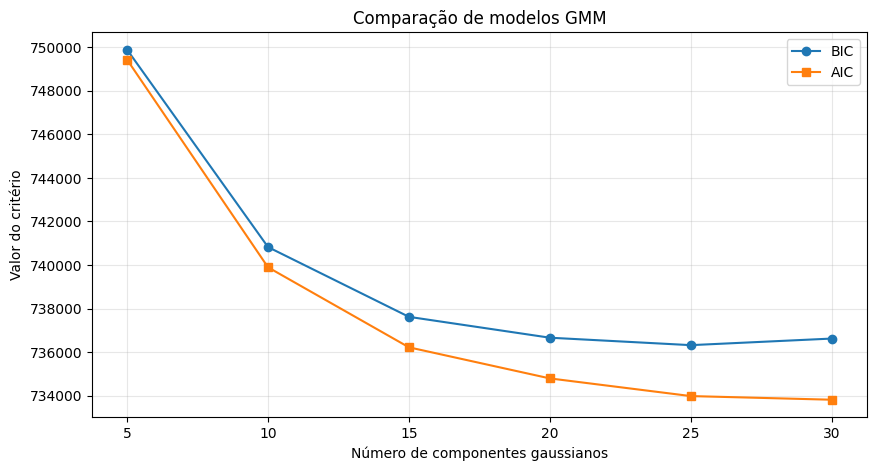

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(results_df['n_components'], results_df['BIC'],
         marker='o', label='BIC')

plt.plot(results_df['n_components'], results_df['AIC'],
         marker='s', label='AIC')

plt.xlabel('Número de componentes gaussianos')
plt.ylabel('Valor do critério')
plt.title('Comparação de modelos GMM')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Testing PCA with 5 components

In [39]:
df_pca5 = PCA_transform(X_scaled, number_of_compoments=5)
df_pca5

,PC0,PC1,PC2,PC3,PC4
0,0.694357,1.254424,0.393031,-0.941709,-0.506020
1,-3.139431,1.086433,0.007441,0.032252,-1.383306
2,-1.294223,-0.268110,-0.509493,-0.924660,-1.549196
3,-3.184718,-0.502834,0.030796,3.057900,-0.246546
4,-0.850054,0.136656,-0.208913,0.195911,-0.537228
...,...,...,...,...,...
88746,-3.720461,-1.995120,0.296020,0.185000,0.522776
88747,-4.912135,-1.116462,0.229542,-0.548814,0.040990
88748,-0.972261,1.797437,-0.348436,1.231331,0.311601
88749,-0.434076,0.238729,-0.477846,0.670078,0.057296


In [40]:
results_2 = []

for k in [5, 10, 15, 20, 25, 30]:
    model_2 = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=5
    )

    model_2.fit(df_pca5)

    results_2.append({
        'n_components': k,
        'BIC': model_2.bic(df_pca5),
        'AIC': model_2.aic(df_pca5),
        'converged': model_2.converged_,
    })

results_df_2 = pd.DataFrame(results_2)
results_df_2

,n_components,BIC,AIC,converged
0,5,1.061386e+06,1.060409e+06,True
1,10,1.017506e+06,1.015543e+06,True
2,15,1.001977e+06,9.990273e+05,True
3,20,9.936370e+05,9.897011e+05,True
4,25,9.865131e+05,9.815909e+05,True
5,30,9.818172e+05,9.759086e+05,True


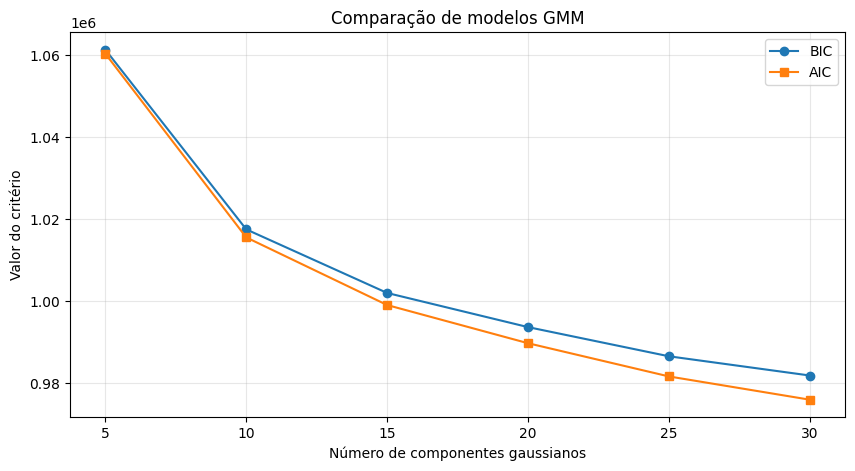

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(results_df_2['n_components'], results_df_2['BIC'],
         marker='o', label='BIC')

plt.plot(results_df_2['n_components'], results_df_2['AIC'],
         marker='s', label='AIC')

plt.xlabel('Número de componentes gaussianos')
plt.ylabel('Valor do critério')
plt.title('Comparação de modelos GMM')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- Após analisar os GMMs com PCAs com 3 e 5 componentes, percebemos que para o PCA com 5 componentes, o número de componentes gaussianos que retorna o valor mais baixo do BIC é com 30, já o PCA com 3 componentes 25 componentes gaussianos retornam o BIC mais baixo

# Avaliando o davies boulding score com o PCA de 5 componentes

In [ ]:
results_db = []

for k in [15, 25, 30]:

    model = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=5
    )

    model.fit(df_pca5)

    labels = model.predict(df_pca5)

    db_score = davies_bouldin_score(
        df_pca5,
        labels
    )

    results_db.append({
        'n_components': k,
        'davies_bouldin': db_score,
        'n_clusters_found': len(np.unique(labels))
    })

results_db_df = pd.DataFrame(results_db)
results_db_df

,n_components,davies_bouldin,n_clusters_found
0,15,2.028566,15
1,25,2.043709,25
2,30,2.073374,30


In [44]:
cluster_counts = pd.Series(labels).value_counts().sort_index()

print(cluster_counts)

0     1082
1     5881
2     3326
3     2677
4     4819
5     2449
6     5051
7     1765
8      824
9     3984
10    1632
11    3983
12    2603
13    3409
14     972
15    3237
16    4102
17    1400
18    6178
19    2899
20    2743
21    1315
22    2129
23    3241
24    3554
25    2599
26    2385
27    3447
28    2783
29    2282
Name: count, dtype: int64


# Avaliando o davies boulding score com o PCA de 3 componentes

In [45]:
results_db_2 = []

for k in [15, 25, 30]:

    model_2 = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=5
    )

    model_2.fit(df_pca3)

    labels_2 = model_2.predict(df_pca3)

    db_score_2 = davies_bouldin_score(
        df_pca3,
        labels_2
    )

    results_db_2.append({
        'n_components': k,
        'davies_bouldin': db_score_2,
        'n_clusters_found': len(np.unique(labels_2))
    })

results_db_df_2 = pd.DataFrame(results_db_2)
results_db_df_2

,n_components,davies_bouldin,n_clusters_found
0,15,1.347828,15
1,25,1.265526,25
2,30,1.171124,30


In [46]:
cluster_sizes = pd.Series(labels_2).value_counts()

print(cluster_sizes.describe())

count      30.000000
mean     2958.366667
std      1593.118574
min       144.000000
25%      1816.000000
50%      2713.500000
75%      4322.000000
max      6240.000000
Name: count, dtype: float64


In [47]:
cluster_sizes = pd.Series(labels_2).value_counts().sort_values()

print(cluster_sizes)

20     144
19     723
14     752
17     961
22    1144
2     1462
3     1524
7     1777
15    1933
21    2236
6     2270
8     2380
29    2548
12    2563
5     2627
24    2800
0     2936
28    3002
11    3058
1     3636
18    3874
10    4247
16    4347
26    4390
23    4580
9     4857
25    4900
13    5136
27    5704
4     6240
Name: count, dtype: int64


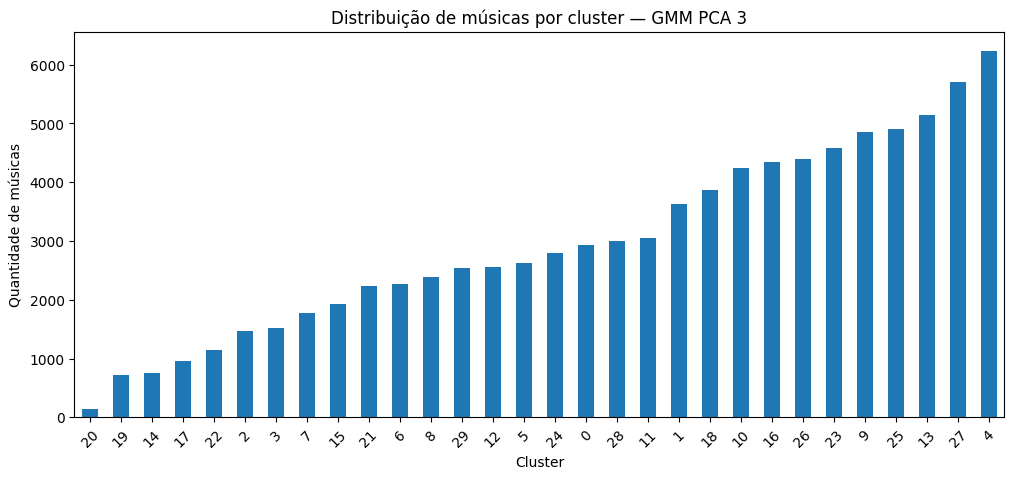

In [48]:
plt.figure(figsize=(12, 5))

cluster_sizes.plot(kind='bar')

plt.title('Distribuição de músicas por cluster — GMM PCA 3')
plt.xlabel('Cluster')
plt.ylabel('Quantidade de músicas')
plt.xticks(rotation=45)
plt.show()

## Avaliando o silhouete score para o pca com 3 componentes

In [50]:
labels_2 = model_2.predict(df_pca3)

silhouette_pca3 = silhouette_score(
    df_pca3,
    labels_2,
    sample_size=5000,
    random_state=42
)

print(f"Silhouette PCA 3: {silhouette_pca3:.4f}")

Silhouette PCA 3: 0.1863


In [51]:
results_silhouette_pca3 = []

for k in [15, 25, 30]:

    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=5
    )

    gmm.fit(df_pca3)

    labels_2 = gmm.predict(df_pca3)

    score = silhouette_score(
        df_pca3,
        labels_2,
        sample_size=5000,
        random_state=42
    )

    results_silhouette_pca3.append({
        'n_components': k,
        'silhouette': score
    })

pd.DataFrame(results_silhouette_pca3)

,n_components,silhouette
0,15,0.154011
1,25,0.169264
2,30,0.186284


In [52]:

X_sample = df_pca3.sample(n=5000, random_state=42)

labels_sample = gmm.predict(X_sample)

sil_values = silhouette_samples(X_sample, labels_sample)

print("Silhouette médio:", sil_values.mean())
print("% de valores negativos:", (sil_values < 0).mean() * 100)

Silhouette médio: 0.18628397385309978
% de valores negativos: 20.24


In [53]:
silhouette_analysis = pd.DataFrame({
    'cluster': labels_sample,
    'silhouette': sil_values
})

cluster_analysis = silhouette_analysis.groupby('cluster').agg(
    silhouette_medio=('silhouette', 'mean'),
    percentual_negativo=(
        'silhouette',
        lambda x: (x < 0).mean() * 100
    ),
    n_musicas=('silhouette', 'size')
)

cluster_analysis.sort_values('percentual_negativo', ascending=False)

,silhouette_medio,percentual_negativo,n_musicas
cluster,,,
14,-0.111832,68.888889,45
23,-0.086660,68.512111,289
21,-0.029064,55.371901,121
17,0.002172,52.000000,50
20,0.118921,50.000000,8
28,0.118393,29.447853,163
11,0.129063,27.544910,167
19,0.132936,26.190476,42
5,0.178783,25.490196,153


# Avaliando o davies boulding score com o PCA de 5 componentes

In [54]:
labels_pca5 = model.predict(df_pca5)

silhouette_pca5 = silhouette_score(
    df_pca5,
    labels_pca5,
    sample_size=5000,
    random_state=42
)

print(f"Silhouette PCA 5: {silhouette_pca5:.4f}")

Silhouette PCA 5: 0.0098


In [ ]:
results_silhouette_pca5 = []

for k in [15, 25, 30]:

    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=42,
        n_init=5
    )

    gmm.fit(df_pca5)

    labels = gmm.predict(df_pca5)

    score = silhouette_score(
        df_pca5,
        labels,
        sample_size=5000,
        random_state=42
    )

    results_silhouette_pca5.append({
        'n_components': k,
        'silhouette': score
    })

pd.DataFrame(results_silhouette_pca5)

""
